# Gravity-Offset Step Detection Test

**Goal:** Estimate the sensor's gravity vector from each bag's initial stillness period (adaptively detected), subtract it as a fixed offset, and use the resulting dynamic acceleration for step detection. This removes tilt dependence without needing per-sample YPR rotation.

**Adaptive calibration:** Instead of assuming a fixed stillness duration, we detect how long each bag is actually still at the start by monitoring rolling standard deviation of acceleration magnitude. We use 80% of the detected stillness window for calibration — the margin avoids contamination from the transition to walking.

**Approach:**
1. Detect stillness duration per bag via rolling std threshold
2. Use 80% of detected stillness to estimate gravity vector (mean acceleration)
3. Subtract this gravity vector from all acceleration samples → dynamic acceleration
4. Compute magnitude of dynamic acceleration for step detection
5. Compare with original body-frame magnitude approach using all 3 classifiers

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from mcap_ros2.reader import read_ros2_messages
from pathlib import Path
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

def read_bag(bag_path):
    ts, gyro, acc, ypr = [], [], [], []
    for msg in read_ros2_messages(str(bag_path)):
        if msg.channel.topic != '/imu':
            continue
        m = msg.ros_msg
        ts.append(m.header.stamp.sec + m.header.stamp.nanosec * 1e-9)
        gyro.append([m.imu.angular_velocity.x, m.imu.angular_velocity.y, m.imu.angular_velocity.z])
        acc.append([m.imu.linear_acceleration.x, m.imu.linear_acceleration.y, m.imu.linear_acceleration.z])
        raw = m.raw
        if raw.startswith('$VNYMR'):
            parts = raw.split(',')
            ypr.append([float(parts[1]), float(parts[2]), float(parts[3])])

    ts = np.array(ts)
    t0 = ts[0]
    ts -= t0

    taps = []
    for msg in read_ros2_messages(str(bag_path)):
        if msg.channel.topic != '/tap':
            continue
        m = msg.ros_msg
        taps.append(m.stamp.sec + m.stamp.nanosec * 1e-9 - t0)

    return {
        'timestamps': ts,
        'linear_accelerations': np.array(acc),
        'angular_velocities': np.array(gyro),
        'yaw_pitch_roll': np.array(ypr) if ypr else np.array([]).reshape(0, 3),
        'tap_times': np.array(taps),
        'sample_rate': len(ts) / ts[-1] if ts[-1] > 0 else 40.0,
    }

BAG_PATHS = [
    ('my_bag',   Path('my_bag/rosbag2_2026_11_10-14_04_54_0.mcap')),
    ('14_14_01', Path('rosbag2_2026_11_10-14_14_01/rosbag2_2026_11_10-14_14_01_0.mcap')),
    ('14_14_58', Path('rosbag2_2026_11_10-14_14_58/rosbag2_2026_11_10-14_14_58_0.mcap')),
    ('14_21_45', Path('rosbag2_2026_11_10-14_21_45/rosbag2_2026_11_10-14_21_45_0.mcap')),
    ('14_26_26', Path('rosbag2_2026_11_10-14_26_26/rosbag2_2026_11_10-14_26_26_0.mcap')),
    ('14_30_34', Path('rosbag2_2026_11_10-14_30_34/rosbag2_2026_11_10-14_30_34_0.mcap')),
    ('14_32_26', Path('rosbag2_2026_11_10-14_32_26/rosbag2_2026_11_10-14_32_26_0.mcap')),
]

bags = {}
for name, path in BAG_PATHS:
    bags[name] = read_bag(path)
    b = bags[name]
    b['accel_mag'] = np.linalg.norm(b['linear_accelerations'], axis=1)
    b['gyro_mag'] = np.linalg.norm(b['angular_velocities'], axis=1)
    print(f"{name:12s}  IMU={len(b['timestamps']):5d}  "
          f"taps={len(b['tap_times']):3d}  duration={b['timestamps'][-1]:.1f}s")

my_bag        IMU=18286  taps=200  duration=457.1s
14_14_01      IMU= 1619  taps= 32  duration=40.4s
14_14_58      IMU= 2379  taps= 50  duration=59.4s
14_21_45      IMU= 2293  taps= 40  duration=57.3s
14_26_26      IMU= 3369  taps= 58  duration=84.2s
14_30_34      IMU= 3666  taps= 62  duration=92.0s
14_32_26      IMU= 3605  taps= 62  duration=90.1s


## Adaptive Stillness Calibration → Gravity Estimate

Instead of assuming a fixed 1.5s stillness window, we **detect** how long each bag is actually still at the start by monitoring the rolling standard deviation of acceleration magnitude. When the person starts walking, the variance jumps sharply. We find that transition point and use 80% of the detected stillness window for gravity estimation — the 80% margin avoids contamination from the transition edge.

In [22]:
CALIB_FRACTION = 0.80  # use 80% of detected stillness
ROLL_WIN = 10          # rolling-std window in samples (~0.25s at 40 Hz)
THRESH_MULT = 5.0      # stillness ends when rolling std > THRESH_MULT × minimum rolling std

def detect_stillness_end(accel_mag, roll_win=ROLL_WIN, thresh_mult=THRESH_MULT):
    """Find the sample index where stillness ends (walking begins).
    Uses rolling std of accel magnitude — stillness has very low variance."""
    n = len(accel_mag)
    if n < roll_win * 3:
        return roll_win  # fallback: too short
    
    # Rolling std over a small window
    roll_std = np.array([accel_mag[i:i+roll_win].std() for i in range(n - roll_win + 1)])
    
    # Baseline: minimum rolling std in the first few seconds (should be in stillness)
    # Look at first 3s worth of rolling std values to find the quiet floor
    first_3s = min(int(3.0 * 40), len(roll_std))
    baseline_std = np.median(roll_std[:first_3s])
    
    if baseline_std < 1e-6:
        baseline_std = 1e-3  # safety floor
    
    threshold = baseline_std * thresh_mult
    
    # Find first index where rolling std exceeds threshold
    exceed = np.where(roll_std > threshold)[0]
    if len(exceed) == 0:
        # Never exceeded — entire signal is "still" (unlikely), use first 2s
        return min(int(2.0 * 40), n)
    
    return exceed[0]

print(f"{'Bag':12s} {'Stillness':>10s} {'Calib (80%)':>12s} {'Gravity vector (x,y,z)':>30s} {'|g|':>8s} {'Tilt from Z':>12s}")
print('-' * 95)

for name, b in bags.items():
    ts = b['timestamps']
    acc = b['linear_accelerations']
    amag = b['accel_mag']
    
    # Detect where stillness ends
    still_end_idx = detect_stillness_end(amag)
    still_duration = ts[still_end_idx] if still_end_idx < len(ts) else ts[-1]
    
    # Use 80% of detected stillness
    calib_end_idx = int(still_end_idx * CALIB_FRACTION)
    calib_end_idx = max(calib_end_idx, 10)  # at least 10 samples
    calib_duration = ts[min(calib_end_idx, len(ts)-1)]
    
    gravity_vec = acc[:calib_end_idx].mean(axis=0)
    gravity_mag = np.linalg.norm(gravity_vec)
    
    cos_tilt = abs(gravity_vec[2]) / gravity_mag
    tilt_deg = np.degrees(np.arccos(np.clip(cos_tilt, -1, 1)))
    
    # Also compute accel/gyro noise floor from calibration window
    calib_accel_std = np.linalg.norm(acc[:calib_end_idx], axis=1).std()
    calib_gyro_std = np.linalg.norm(b['angular_velocities'][:calib_end_idx], axis=1).std()
    
    b['gravity_vec'] = gravity_vec
    b['gravity_mag'] = gravity_mag
    b['n_static'] = calib_end_idx
    b['tilt_deg'] = tilt_deg
    b['still_end_idx'] = still_end_idx
    b['calib_accel_std'] = calib_accel_std
    b['calib_gyro_std'] = calib_gyro_std
    
    print(f"{name:12s} {still_duration:8.2f}s → {calib_duration:8.2f}s  "
          f"[{gravity_vec[0]:+7.3f}, {gravity_vec[1]:+7.3f}, {gravity_vec[2]:+7.3f}] "
          f"{gravity_mag:8.3f} {tilt_deg:10.1f}°")

print(f"\nAdaptive calibration: detected stillness per bag, used {CALIB_FRACTION*100:.0f}% for gravity estimate")
print(f"Detection: rolling std (window={ROLL_WIN} samples) exceeding {THRESH_MULT}× baseline")

Bag           Stillness  Calib (80%)         Gravity vector (x,y,z)      |g|  Tilt from Z
-----------------------------------------------------------------------------------------------
my_bag           4.57s →     3.65s  [ +4.548,  -7.810,  -4.466]   10.081       63.7°
14_14_01         2.52s →     2.00s  [ +1.033,  -9.719,  -1.288]    9.858       82.5°
14_14_58         2.77s →     2.20s  [ +1.050,  -9.708,  -1.376]    9.862       82.0°
14_21_45         4.85s →     3.87s  [ +1.742,  -9.654,  -0.583]    9.827       86.6°
14_26_26         3.27s →     2.60s  [ +2.407,  -9.506,  -0.574]    9.822       86.7°
14_30_34         2.40s →     1.90s  [ +3.669,  -9.005,  -1.949]    9.917       78.7°
14_32_26         2.25s →     1.80s  [ +3.465,  -9.021,  -2.297]    9.933       76.6°

Adaptive calibration: detected stillness per bag, used 80% for gravity estimate
Detection: rolling std (window=10 samples) exceeding 5.0× baseline


## Clean my_bag, Then Apply Gravity Subtraction to All Bags

Keep only the first 70 taps from my_bag to reduce its dominance in training. Gravity was estimated adaptively from each bag's detected stillness period (before any trimming) so the calibration is clean.

In [23]:
MAX_TAPS = 70  # keep only the first 70 taps from my_bag

# Clean my_bag (same as main notebook)
b = bags['my_bag']
taps = b['tap_times']
clean_taps = [taps[0]]
for i in range(1, len(taps)):
    if taps[i] - clean_taps[-1] >= 0.3:
        clean_taps.append(taps[i])
clean_taps = np.array(clean_taps)

# Keep only the first MAX_TAPS taps
clean_taps = clean_taps[:MAX_TAPS]
print(f"my_bag: {len(taps)} raw taps → {len(clean_taps)} after dedup + first-{MAX_TAPS} trim")

buffer = 2.0
t_start = clean_taps[0] - buffer
t_end = clean_taps[-1] + buffer
ts = b['timestamps']
trim_mask = (ts >= t_start) & (ts <= t_end)

new_t0 = ts[trim_mask][0]
b['timestamps'] = ts[trim_mask] - new_t0
b['linear_accelerations'] = b['linear_accelerations'][trim_mask]
b['angular_velocities'] = b['angular_velocities'][trim_mask]
if len(b['yaw_pitch_roll']) > 0:
    ypr_trim = trim_mask[:len(b['yaw_pitch_roll'])]
    b['yaw_pitch_roll'] = b['yaw_pitch_roll'][ypr_trim]
b['tap_times'] = clean_taps - new_t0
b['accel_mag'] = np.linalg.norm(b['linear_accelerations'], axis=1)
b['gyro_mag'] = np.linalg.norm(b['angular_velocities'], axis=1)
b['sample_rate'] = len(b['timestamps']) / b['timestamps'][-1]

print(f"my_bag cleaned: {len(b['timestamps'])} samples, {len(b['tap_times'])} taps, {b['timestamps'][-1]:.1f}s")
print(f"Gravity was estimated BEFORE trimming using adaptive stillness detection ({b['n_static']} calibration samples)")

# Apply gravity subtraction to ALL bags using the pre-estimated gravity vector
print(f"\nApplying gravity subtraction:")
for name, b in bags.items():
    dyn = b['linear_accelerations'] - b['gravity_vec']
    b['dynamic_accel'] = dyn
    b['dyn_accel_mag'] = np.linalg.norm(dyn, axis=1)
    
    print(f"  {name:12s}  body_mag_mean={b['accel_mag'].mean():.3f}  "
          f"dyn_mag_mean={b['dyn_accel_mag'].mean():.3f}  "
          f"tilt={b['tilt_deg']:.1f}°")

my_bag: 200 raw taps → 70 after dedup + first-70 trim
my_bag cleaned: 3355 samples, 70 taps, 83.8s
Gravity was estimated BEFORE trimming using adaptive stillness detection (146 calibration samples)

Applying gravity subtraction:
  my_bag        body_mag_mean=10.415  dyn_mag_mean=3.347  tilt=63.7°
  14_14_01      body_mag_mean=10.121  dyn_mag_mean=2.692  tilt=82.5°
  14_14_58      body_mag_mean=10.085  dyn_mag_mean=2.532  tilt=82.0°
  14_21_45      body_mag_mean=10.035  dyn_mag_mean=2.348  tilt=86.6°
  14_26_26      body_mag_mean=10.066  dyn_mag_mean=2.611  tilt=86.7°
  14_30_34      body_mag_mean=10.108  dyn_mag_mean=1.989  tilt=78.7°
  14_32_26      body_mag_mean=10.121  dyn_mag_mean=1.858  tilt=76.6°


## Compare Signals: Body-Frame Magnitude vs Gravity-Subtracted

Key question: does subtracting the stationary gravity offset produce a more consistent signal across bags with different sensor tilts?

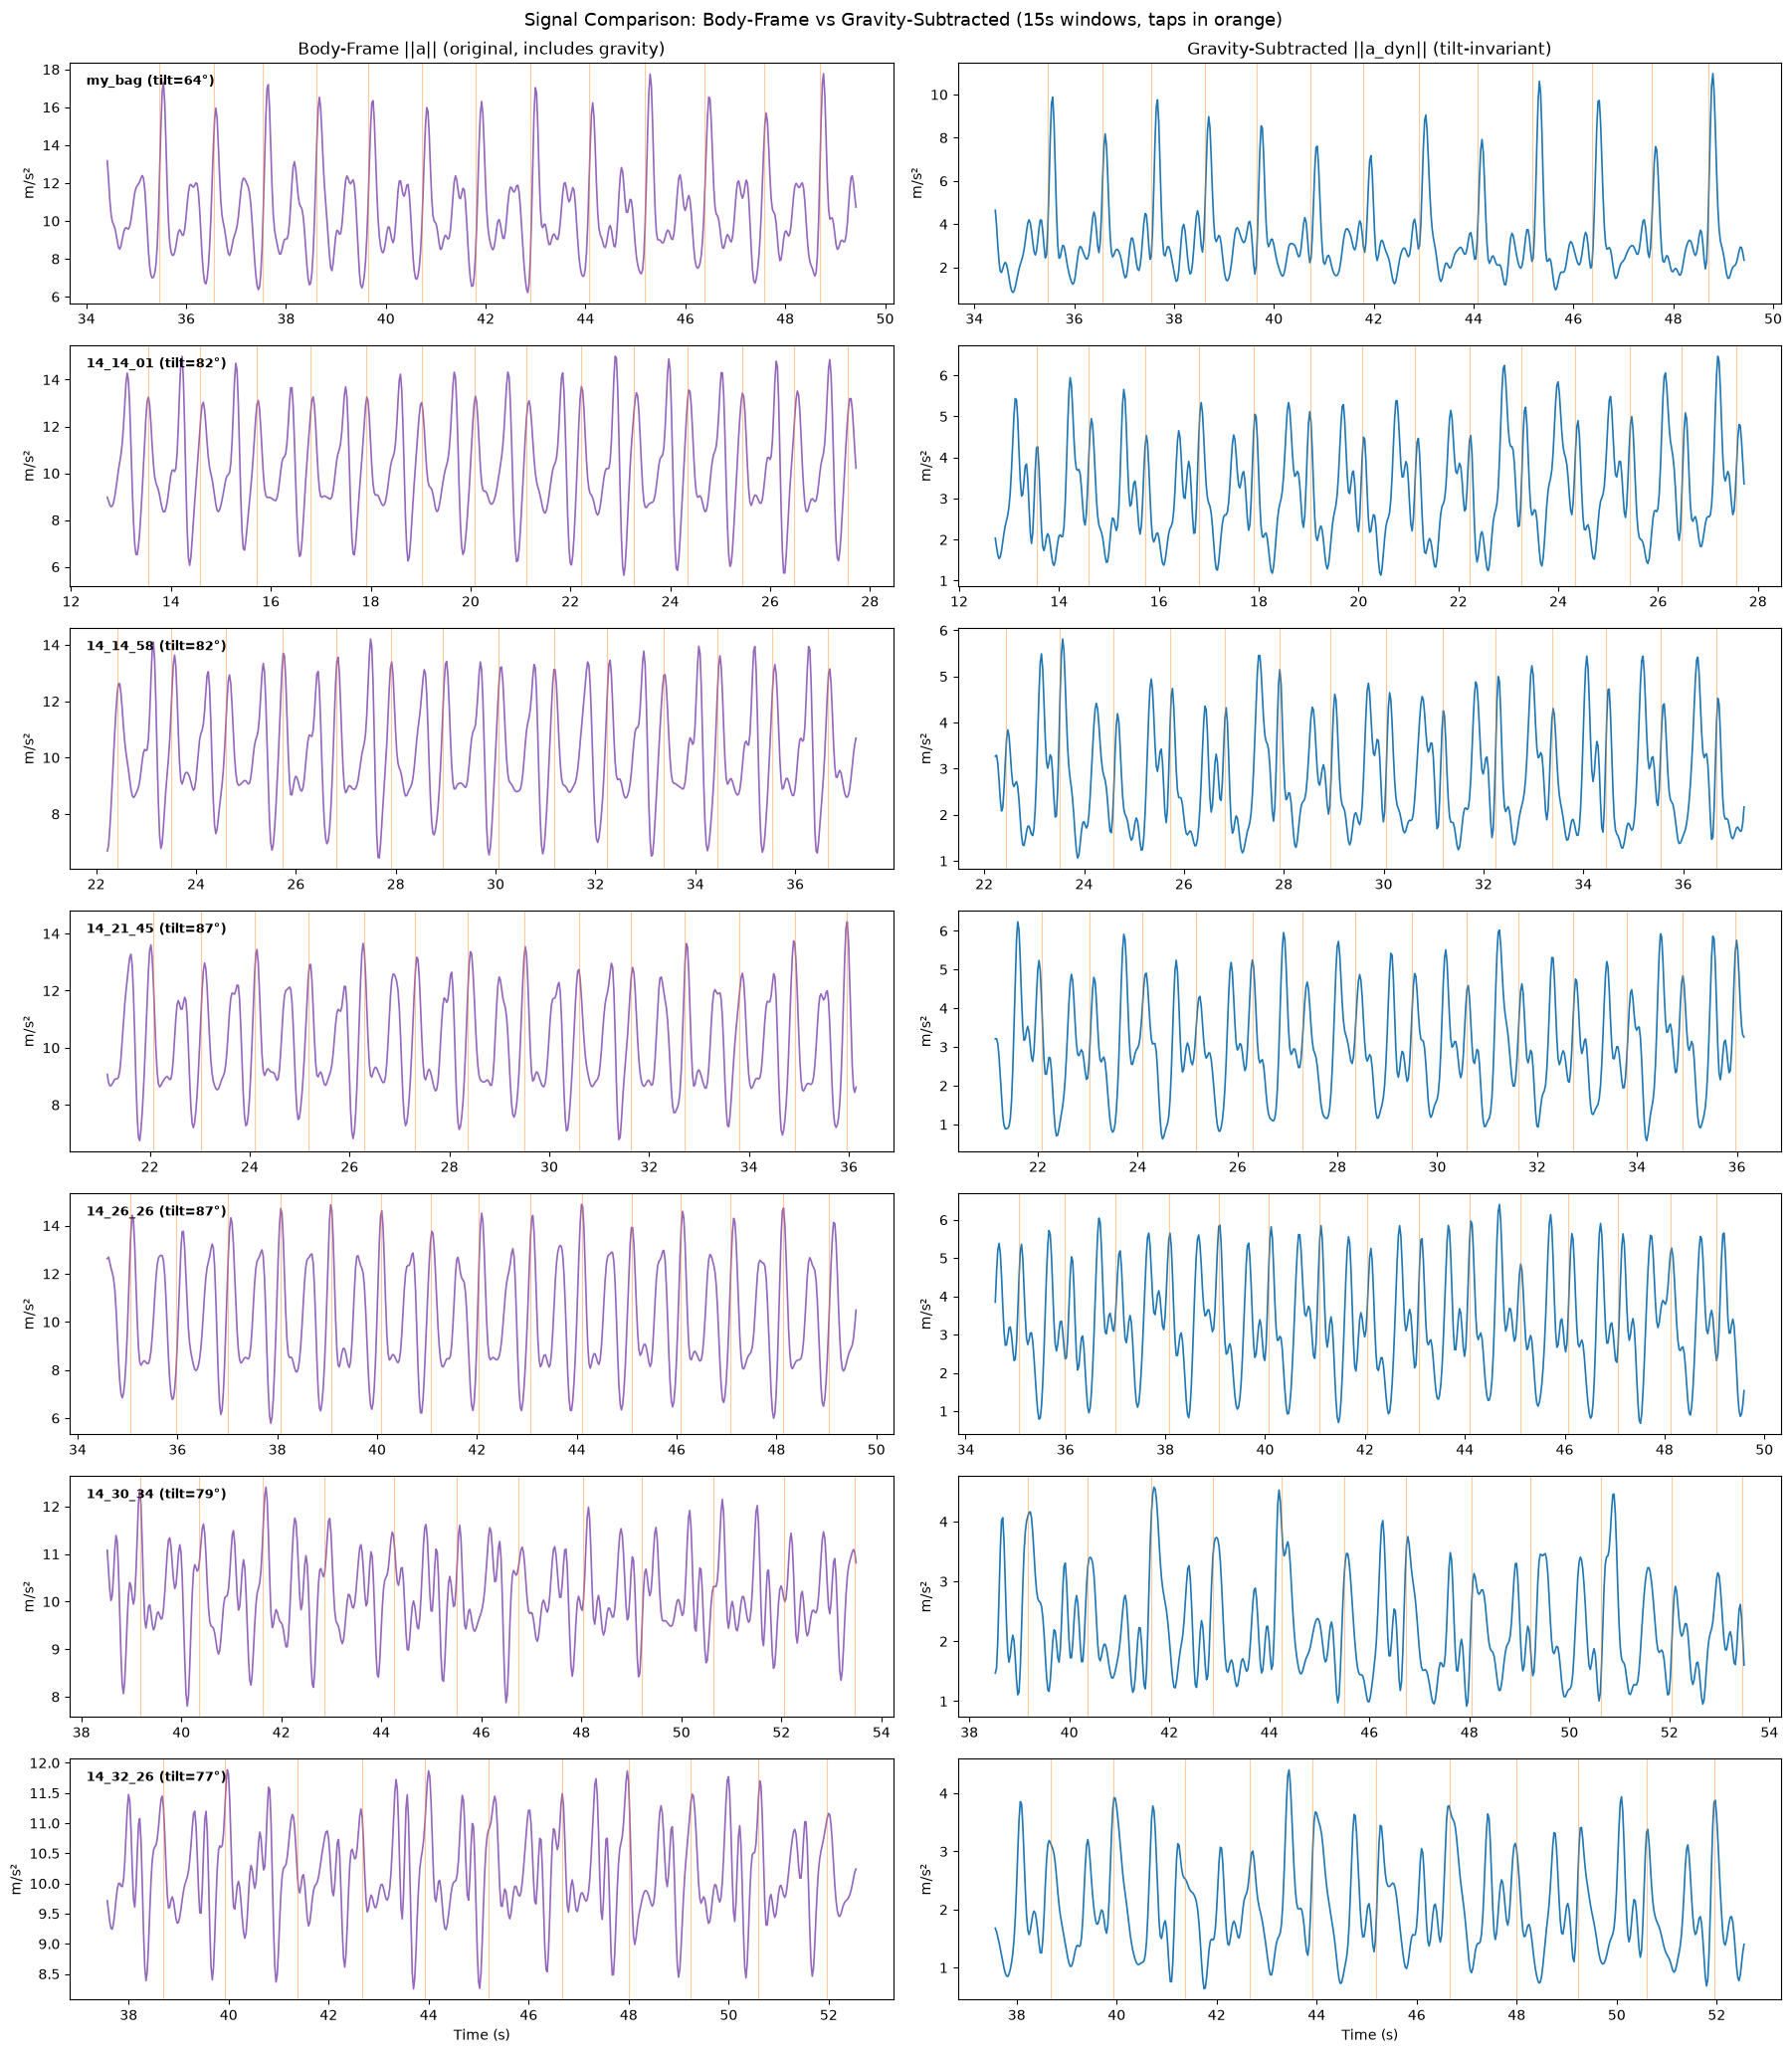

In [24]:
def lowpass_filter(signal, cutoff=5.0, fs=40.0, order=4):
    nyq = fs / 2.0
    b_coef, a_coef = butter(order, cutoff / nyq, btype='low')
    return filtfilt(b_coef, a_coef, signal)

# Filter both signals for all bags
for name, b in bags.items():
    fs = b['sample_rate']
    b['accel_mag_filt'] = lowpass_filter(b['accel_mag'], cutoff=5.0, fs=fs)
    b['dyn_mag_filt'] = lowpass_filter(b['dyn_accel_mag'], cutoff=5.0, fs=fs)
    b['gyro_mag_filt'] = lowpass_filter(b['gyro_mag'], cutoff=5.0, fs=fs)

# Side-by-side: body-frame magnitude vs gravity-subtracted dynamic magnitude
fig, axes = plt.subplots(len(bags), 2, figsize=(18, 3 * len(bags)))

for i, (name, b) in enumerate(bags.items()):
    t = b['timestamps']
    mid = t[-1] / 2
    t_start, t_end = mid - 7.5, mid + 7.5
    mask = (t >= t_start) & (t <= t_end)
    
    # Body-frame magnitude (original)
    axes[i, 0].plot(t[mask], b['accel_mag_filt'][mask], color='tab:purple', linewidth=1.2)
    for tap in b['tap_times']:
        if t_start <= tap <= t_end:
            axes[i, 0].axvline(tap, color='tab:orange', alpha=0.4, linewidth=0.8)
    axes[i, 0].set_ylabel('m/s²')
    if i == 0:
        axes[i, 0].set_title('Body-Frame ||a|| (original, includes gravity)')
    axes[i, 0].text(0.02, 0.95, f"{name} (tilt={b['tilt_deg']:.0f}°)",
                     transform=axes[i, 0].transAxes, fontsize=9, va='top', fontweight='bold')
    
    # Gravity-subtracted dynamic magnitude
    axes[i, 1].plot(t[mask], b['dyn_mag_filt'][mask], color='tab:blue', linewidth=1.2)
    for tap in b['tap_times']:
        if t_start <= tap <= t_end:
            axes[i, 1].axvline(tap, color='tab:orange', alpha=0.4, linewidth=0.8)
    axes[i, 1].set_ylabel('m/s²')
    if i == 0:
        axes[i, 1].set_title('Gravity-Subtracted ||a_dyn|| (tilt-invariant)')

axes[-1, 0].set_xlabel('Time (s)')
axes[-1, 1].set_xlabel('Time (s)')
plt.suptitle('Signal Comparison: Body-Frame vs Gravity-Subtracted (15s windows, taps in orange)\n', fontsize=13)
plt.tight_layout()
plt.show()

## Signal Consistency Check

Compare the standard deviation across bags — the gravity-subtracted signal should be more consistent since it removes the tilt-dependent gravity offset that varies per bag.

Bag            Tilt  Body mag µ  Body mag σ |  Dyn mag µ  Dyn mag σ |           Gravity (x,y,z)
----------------------------------------------------------------------------------------------------
my_bag        63.7°      10.415       2.407 |      3.347      1.840 | [ +4.55,  -7.81,  -4.47]
14_14_01      82.5°      10.121       1.901 |      2.692      1.402 | [ +1.03,  -9.72,  -1.29]
14_14_58      82.0°      10.085       1.769 |      2.532      1.210 | [ +1.05,  -9.71,  -1.38]
14_21_45      86.6°      10.035       1.461 |      2.348      1.505 | [ +1.74,  -9.65,  -0.58]
14_26_26      86.7°      10.066       1.889 |      2.611      1.657 | [ +2.41,  -9.51,  -0.57]
14_30_34      78.7°      10.108       0.821 |      1.989      0.876 | [ +3.67,  -9.01,  -1.95]
14_32_26      76.6°      10.121       0.704 |      1.858      0.904 | [ +3.47,  -9.02,  -2.30]

Cross-bag coefficient of variation (lower = more consistent):
  Body-frame magnitude mean:  CV = 1.2%
  Gravity-sub magnitude mean: CV = 

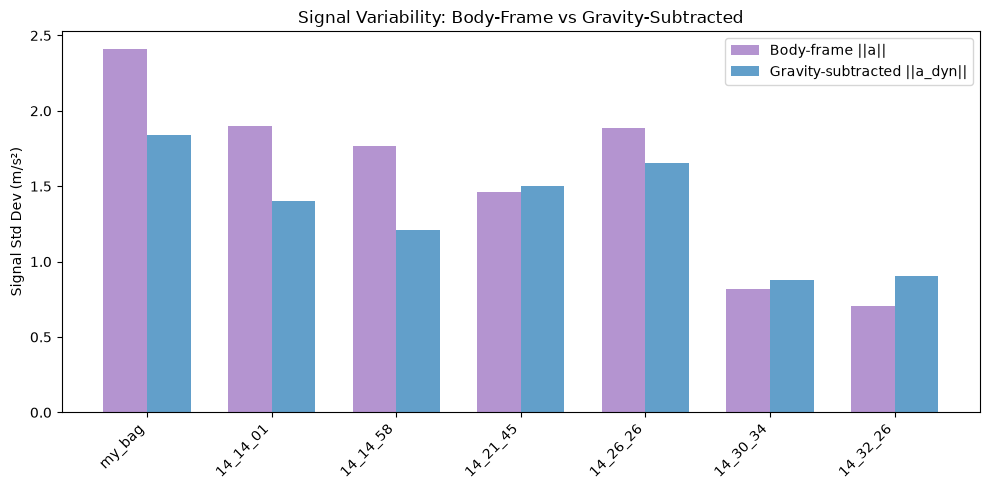

In [25]:
print(f"{'Bag':12s} {'Tilt':>6s} {'Body mag µ':>11s} {'Body mag σ':>11s} | "
      f"{'Dyn mag µ':>10s} {'Dyn mag σ':>10s} | "
      f"{'Gravity (x,y,z)':>25s}")
print('-' * 100)

body_means, body_stds = [], []
dyn_means, dyn_stds = [], []

for name, b in bags.items():
    bm = b['accel_mag_filt']
    dm = b['dyn_mag_filt']
    gv = b['gravity_vec']
    
    body_means.append(bm.mean()); body_stds.append(bm.std())
    dyn_means.append(dm.mean()); dyn_stds.append(dm.std())
    
    print(f"{name:12s} {b['tilt_deg']:5.1f}° {bm.mean():11.3f} {bm.std():11.3f} | "
          f"{dm.mean():10.3f} {dm.std():10.3f} | "
          f"[{gv[0]:+6.2f}, {gv[1]:+6.2f}, {gv[2]:+6.2f}]")

print(f"\nCross-bag coefficient of variation (lower = more consistent):")
print(f"  Body-frame magnitude mean:  CV = {np.std(body_means)/np.mean(body_means)*100:.1f}%")
print(f"  Gravity-sub magnitude mean: CV = {np.std(dyn_means)/np.mean(dyn_means)*100:.1f}%")
print(f"  Body-frame magnitude std:   CV = {np.std(body_stds)/np.mean(body_stds)*100:.1f}%")
print(f"  Gravity-sub magnitude std:  CV = {np.std(dyn_stds)/np.mean(dyn_stds)*100:.1f}%")

# Bar chart of std comparison
fig, ax = plt.subplots(figsize=(10, 5))
bag_names = list(bags.keys())
x = np.arange(len(bag_names))
width = 0.35
ax.bar(x - width/2, body_stds, width, label='Body-frame ||a||', color='tab:purple', alpha=0.7)
ax.bar(x + width/2, dyn_stds, width, label='Gravity-subtracted ||a_dyn||', color='tab:blue', alpha=0.7)
ax.set_xticks(x)
ax.set_xticklabels(bag_names, rotation=45, ha='right')
ax.set_ylabel('Signal Std Dev (m/s²)')
ax.set_title('Signal Variability: Body-Frame vs Gravity-Subtracted')
ax.legend()
plt.tight_layout()
plt.show()

## Peak Detection Comparison

Run the same peak detector on body-frame magnitude and gravity-subtracted dynamic magnitude. Compare precision/recall/F1.

In [26]:
def detect_steps(signal_filt, fs, min_height_above_mean=0.5, min_distance_sec=0.35, min_prominence=0.3):
    mean_val = signal_filt.mean()
    min_height = mean_val + min_height_above_mean
    min_distance = int(min_distance_sec * fs)
    peaks, properties = find_peaks(
        signal_filt, height=min_height, distance=min_distance, prominence=min_prominence,
    )
    return peaks, properties

def detect_steps_dynamic(signal_filt, fs, min_height_above_mean=0.3, min_distance_sec=0.35, min_prominence=0.2):
    """Tuned for dynamic acceleration (centered around 0, not ~10)."""
    mean_val = signal_filt.mean()
    min_height = mean_val + min_height_above_mean
    min_distance = int(min_distance_sec * fs)
    peaks, properties = find_peaks(
        signal_filt, height=min_height, distance=min_distance, prominence=min_prominence,
    )
    return peaks, properties

def match_detections_to_taps(detected_times, tap_times, tolerance_sec=0.3):
    tp = 0
    matched_taps = set()
    for det_t in detected_times:
        diffs = np.abs(tap_times - det_t)
        best_idx = np.argmin(diffs)
        if diffs[best_idx] <= tolerance_sec and best_idx not in matched_taps:
            tp += 1
            matched_taps.add(best_idx)
    fp = len(detected_times) - tp
    fn = len(tap_times) - tp
    return tp, fp, fn

print(f"{'Bag':12s} {'Signal':15s} {'Taps':>5s} {'Det':>5s} {'TP':>5s} {'FP':>5s} {'FN':>5s} {'Prec':>7s} {'Recall':>7s} {'F1':>7s}")
print('-' * 90)

for name, b in bags.items():
    fs = b['sample_rate']
    n_taps = len(b['tap_times'])
    
    # Original body-frame magnitude
    peaks_body, props_body = detect_steps(b['accel_mag_filt'], fs)
    det_times_body = b['timestamps'][peaks_body]
    tp, fp, fn = match_detections_to_taps(det_times_body, b['tap_times'])
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    print(f"{name:12s} {'body-frame mag':15s} {n_taps:5d} {len(peaks_body):5d} {tp:5d} {fp:5d} {fn:5d} {prec:7.3f} {rec:7.3f} {f1:7.3f}")
    b['detected_peaks_body'] = peaks_body
    b['peak_props_body'] = props_body
    
    # World-frame dynamic magnitude
    peaks_dyn, props_dyn = detect_steps_dynamic(b['dyn_mag_filt'], fs)
    det_times_dyn = b['timestamps'][peaks_dyn]
    tp, fp, fn = match_detections_to_taps(det_times_dyn, b['tap_times'])
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    print(f"{'':12s} {'world-frame dyn':15s} {'':5s} {len(peaks_dyn):5d} {tp:5d} {fp:5d} {fn:5d} {prec:7.3f} {rec:7.3f} {f1:7.3f}")
    b['detected_peaks_dyn'] = peaks_dyn
    b['peak_props_dyn'] = props_dyn
    
    print()

Bag          Signal           Taps   Det    TP    FP    FN    Prec  Recall      F1
------------------------------------------------------------------------------------------
my_bag       body-frame mag     70   144    70    74     0   0.486   1.000   0.654
             world-frame dyn         100    70    30     0   0.700   1.000   0.824

14_14_01     body-frame mag     32    64    32    32     0   0.500   1.000   0.667
             world-frame dyn          63    32    31     0   0.508   1.000   0.674

14_14_58     body-frame mag     50   100    50    50     0   0.500   1.000   0.667
             world-frame dyn          99    50    49     0   0.505   1.000   0.671

14_21_45     body-frame mag     40    81    40    41     0   0.494   1.000   0.661
             world-frame dyn          80    40    40     0   0.500   1.000   0.667

14_26_26     body-frame mag     58   125    58    67     0   0.464   1.000   0.634
             world-frame dyn         123    57    66     1   0.463   0.983 

## ML Pipeline: LOBO Comparison — All Classifiers

Run the full pipeline (feature extraction → ML classification → LOBO evaluation) on both signal types with all three classifiers: Logistic Regression, Gradient Boosting, and Random Forest. Includes per-fold classification reports and a summary comparison.

In [27]:
def extract_features(peaks, accel_filt, gyro_filt, props, n, window_samples=10):
    features = []
    for i, pk in enumerate(peaks):
        lo = max(0, pk - window_samples)
        hi = min(n, pk + window_samples + 1)
        win_a = accel_filt[lo:hi]
        win_g = gyro_filt[lo:hi]

        a_std = max(win_a.std(), 1e-6)
        a_z = (win_a - win_a.mean()) / a_std
        win_accel_skew = float(np.mean(a_z**3))
        win_accel_kurt = float(np.mean(a_z**4)) - 3.0
        gyro_accel_corr = float(np.corrcoef(win_a, win_g)[0, 1]) if len(win_a) > 1 else 0.0
        peak_sharpness = float(accel_filt[pk] - 0.5 * (accel_filt[max(0, pk-1)] + accel_filt[min(n-1, pk+1)]))

        feat = [
            accel_filt[pk],
            props['prominences'][i],
            win_a.mean(),
            win_a.std(),
            win_a.max() - win_a.min(),
            win_g.mean(),
            win_g.std(),
            accel_filt[pk] / win_a.mean() if abs(win_a.mean()) > 1e-6 else 1.0,
            win_accel_skew,
            win_accel_kurt,
            gyro_accel_corr,
            peak_sharpness,
        ]
        features.append(feat)
    return np.array(features) if features else np.array([]).reshape(0, 12)

def label_peaks(detected_peak_times, tap_times, tolerance_sec=0.3):
    labels = np.zeros(len(detected_peak_times), dtype=int)
    used_taps = set()
    for i, det_t in enumerate(detected_peak_times):
        diffs = np.abs(tap_times - det_t)
        best_idx = np.argmin(diffs)
        if diffs[best_idx] <= tolerance_sec and best_idx not in used_taps:
            labels[i] = 1
            used_taps.add(best_idx)
    return labels

# Extract features and labels for both signal types
for name, b in bags.items():
    n = len(b['accel_mag_filt'])
    
    # Body-frame features (original)
    b['features_body'] = extract_features(
        b['detected_peaks_body'], b['accel_mag_filt'], b['gyro_mag_filt'],
        b['peak_props_body'], n)
    b['labels_body'] = label_peaks(b['timestamps'][b['detected_peaks_body']], b['tap_times'])
    
    # World-frame features
    b['features_dyn'] = extract_features(
        b['detected_peaks_dyn'], b['dyn_mag_filt'], b['gyro_mag_filt'],
        b['peak_props_dyn'], n)
    b['labels_dyn'] = label_peaks(b['timestamps'][b['detected_peaks_dyn']], b['tap_times'])
    
    print(f"{name:12s}  body: {len(b['features_body'])} peaks ({b['labels_body'].sum()} true)  "
          f"world: {len(b['features_dyn'])} peaks ({b['labels_dyn'].sum()} true)")

my_bag        body: 144 peaks (70 true)  world: 100 peaks (70 true)
14_14_01      body: 64 peaks (32 true)  world: 63 peaks (32 true)
14_14_58      body: 100 peaks (50 true)  world: 99 peaks (50 true)
14_21_45      body: 81 peaks (40 true)  world: 80 peaks (40 true)
14_26_26      body: 125 peaks (58 true)  world: 123 peaks (57 true)
14_30_34      body: 127 peaks (61 true)  world: 125 peaks (57 true)
14_32_26      body: 124 peaks (61 true)  world: 124 peaks (61 true)


LEAVE-ONE-BAG-OUT: Body-Frame vs Gravity-Subtracted × All Classifiers

────────────────────────────────────────────────────────────────────────────────────────────────────
Hold-out: my_bag (tilt=64°, 70 true steps)
────────────────────────────────────────────────────────────────────────────────────────────────────

  Signal: body  |  Train: 621 (302 pos)  Test: 144 (70 pos)
    LogReg          predicted= 49  err= -30.0%  P=0.816  R=0.571  F1=0.672  (train_F1=0.920)
    GBClassifier    predicted= 40  err= -42.9%  P=0.700  R=0.400  F1=0.509  (train_F1=0.979)
    RandomForest    predicted= 39  err= -44.3%  P=0.744  R=0.414  F1=0.532  (train_F1=1.000)

    Classification Report (body, GBClassifier):
                  precision    recall  f1-score   support
    
      false_peak       0.60      0.84      0.70        74
       true_step       0.70      0.40      0.51        70
    
        accuracy                           0.62       144
       macro avg       0.65      0.62      0.60      

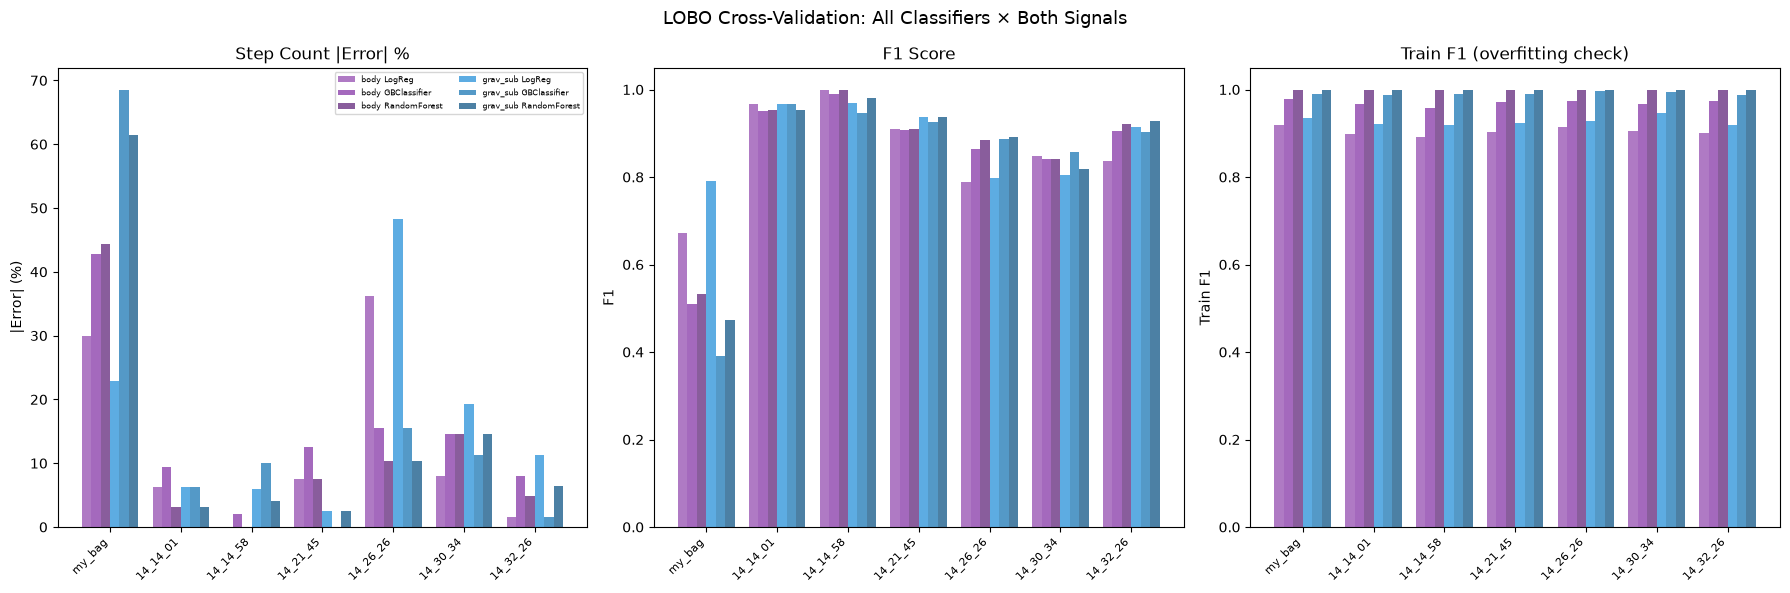

In [28]:
# LOBO cross-validation — all 3 classifiers × 2 signal types
all_bag_names = list(bags.keys())

CLASSIFIERS = {
    'LogReg': lambda: LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42),
    'GBClassifier': lambda: GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        min_samples_leaf=10, random_state=42),
    'RandomForest': lambda: RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=42),
}

SIGNAL_TYPES = [
    ('body', 'features_body', 'labels_body'),
    ('grav_sub', 'features_dyn', 'labels_dyn'),
]

# Store all results: results[signal][clf_name] = {'errors': [], 'f1s': [], 'precs': [], 'recs': []}
results = {}
for sig, _, _ in SIGNAL_TYPES:
    results[sig] = {}
    for clf_name in CLASSIFIERS:
        results[sig][clf_name] = {'errors': [], 'f1s': [], 'precs': [], 'recs': [],
                                   'train_f1s': [], 'preds': {}, 'labels': {}}

print("=" * 100)
print("LEAVE-ONE-BAG-OUT: Body-Frame vs Gravity-Subtracted × All Classifiers")
print("=" * 100)

for hold_out in all_bag_names:
    train_names = [n for n in all_bag_names if n != hold_out]
    true_c = len(bags[hold_out]['tap_times'])
    tilt = bags[hold_out]['tilt_deg']
    
    print(f"\n{'─'*100}")
    print(f"Hold-out: {hold_out} (tilt={tilt:.0f}°, {true_c} true steps)")
    print(f"{'─'*100}")
    
    for signal_type, feat_key, label_key in SIGNAL_TYPES:
        if any(len(bags[n][feat_key]) == 0 for n in all_bag_names):
            continue
        
        X_tr = np.vstack([bags[n][feat_key] for n in train_names])
        y_tr = np.concatenate([bags[n][label_key] for n in train_names])
        X_te = bags[hold_out][feat_key]
        y_te = bags[hold_out][label_key]
        
        sc = StandardScaler()
        X_tr_s = sc.fit_transform(X_tr)
        X_te_s = sc.transform(X_te)
        
        # Sample weights for GB (others use class_weight='balanced')
        n_p = y_tr.sum()
        n_n = len(y_tr) - n_p
        w = np.where(y_tr == 1, n_n / n_p if n_p > 0 else 1.0, 1.0)
        
        print(f"\n  Signal: {signal_type}  |  Train: {len(X_tr)} ({int(y_tr.sum())} pos)  Test: {len(X_te)} ({int(y_te.sum())} pos)")
        
        for clf_name, clf_fn in CLASSIFIERS.items():
            clf = clf_fn()
            if clf_name == 'GBClassifier':
                clf.fit(X_tr_s, y_tr, sample_weight=w)
            else:
                clf.fit(X_tr_s, y_tr)
            
            y_pred = clf.predict(X_te_s)
            y_train_pred = clf.predict(X_tr_s)
            
            pred_c = int(y_pred.sum())
            err = (pred_c - true_c) / true_c * 100
            prec = precision_score(y_te, y_pred, zero_division=0)
            rec = recall_score(y_te, y_pred, zero_division=0)
            f1 = f1_score(y_te, y_pred, zero_division=0)
            train_f1 = f1_score(y_tr, y_train_pred, zero_division=0)
            
            results[signal_type][clf_name]['errors'].append(abs(err))
            results[signal_type][clf_name]['f1s'].append(f1)
            results[signal_type][clf_name]['precs'].append(prec)
            results[signal_type][clf_name]['recs'].append(rec)
            results[signal_type][clf_name]['train_f1s'].append(train_f1)
            results[signal_type][clf_name]['preds'][hold_out] = y_pred
            results[signal_type][clf_name]['labels'][hold_out] = y_te
            
            print(f"    {clf_name:14s}  predicted={pred_c:3d}  err={err:+6.1f}%  "
                  f"P={prec:.3f}  R={rec:.3f}  F1={f1:.3f}  (train_F1={train_f1:.3f})")
        
        # Classification report for best classifier (GB) on this fold
        gb_pred = results[signal_type]['GBClassifier']['preds'][hold_out]
        print(f"\n    Classification Report ({signal_type}, GBClassifier):")
        print("    " + classification_report(y_te, gb_pred, target_names=['false_peak', 'true_step'],
                                              zero_division=0).replace('\n', '\n    '))

# ── SUMMARY TABLE ──
print("\n\n" + "=" * 100)
print("SUMMARY: Mean metrics across all 7 LOBO folds")
print("=" * 100)
print(f"{'Signal':12s} {'Classifier':14s} {'|Error|%':>9s} {'Prec':>7s} {'Recall':>7s} {'F1':>7s} {'Train F1':>9s} {'Overfit?':>9s}")
print('-' * 75)

for sig, _, _ in SIGNAL_TYPES:
    for clf_name in CLASSIFIERS:
        r = results[sig][clf_name]
        mean_err = np.mean(r['errors'])
        mean_p = np.mean(r['precs'])
        mean_r = np.mean(r['recs'])
        mean_f1 = np.mean(r['f1s'])
        mean_tr = np.mean(r['train_f1s'])
        gap = mean_tr - mean_f1
        overfit = "YES" if gap > 0.15 else ("mild" if gap > 0.08 else "no")
        print(f"{sig:12s} {clf_name:14s} {mean_err:8.1f}% {mean_p:7.3f} {mean_r:7.3f} {mean_f1:7.3f} {mean_tr:9.3f} {overfit:>9s}")
    print()

# Excluding my_bag
print(f"\n{'Signal':12s} {'Classifier':14s} {'|Error|%':>9s} {'F1':>7s}   (excluding my_bag)")
print('-' * 55)
for sig, _, _ in SIGNAL_TYPES:
    for clf_name in CLASSIFIERS:
        r = results[sig][clf_name]
        excl_idx = [i for i, n in enumerate(all_bag_names) if n != 'my_bag']
        excl_err = np.mean([r['errors'][i] for i in excl_idx])
        excl_f1 = np.mean([r['f1s'][i] for i in excl_idx])
        print(f"{sig:12s} {clf_name:14s} {excl_err:8.1f}% {excl_f1:7.3f}")
    print()

# ── BAR CHART ──
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
x = np.arange(len(all_bag_names))
n_bars = len(CLASSIFIERS) * len(SIGNAL_TYPES)
total_w = 0.8
bar_w = total_w / n_bars
colors = {'body': {'LogReg': '#9b59b6', 'GBClassifier': '#8e44ad', 'RandomForest': '#6c3483'},
          'grav_sub': {'LogReg': '#3498db', 'GBClassifier': '#2980b9', 'RandomForest': '#1f618d'}}

for ax_idx, (metric, title, ylbl) in enumerate([
    ('errors', 'Step Count |Error| %', '|Error| (%)'),
    ('f1s', 'F1 Score', 'F1'),
    ('train_f1s', 'Train F1 (overfitting check)', 'Train F1'),
]):
    offset = -total_w / 2 + bar_w / 2
    for sig, _, _ in SIGNAL_TYPES:
        for clf_name in CLASSIFIERS:
            vals = results[sig][clf_name][metric]
            label = f"{sig} {clf_name}"
            axes[ax_idx].bar(x + offset, vals, bar_w, label=label,
                            color=colors[sig][clf_name], alpha=0.8)
            offset += bar_w
    axes[ax_idx].set_xticks(x)
    axes[ax_idx].set_xticklabels(all_bag_names, rotation=45, ha='right', fontsize=8)
    axes[ax_idx].set_ylabel(ylbl)
    axes[ax_idx].set_title(title)
    if ax_idx == 1:
        axes[ax_idx].set_ylim(0, 1.05)
    if ax_idx == 2:
        axes[ax_idx].set_ylim(0, 1.05)

axes[0].legend(fontsize=6, ncol=2)
plt.suptitle('LOBO Cross-Validation: All Classifiers × Both Signals', fontsize=13)
plt.tight_layout()
plt.show()

## Learning Curves: Train vs Test F1

Shows how train and test F1 change as we add more bags to training. This reveals whether the model is overfitting (large train-test gap) or underfitting (both low). Each point averages over all possible held-out bags at that training set size.

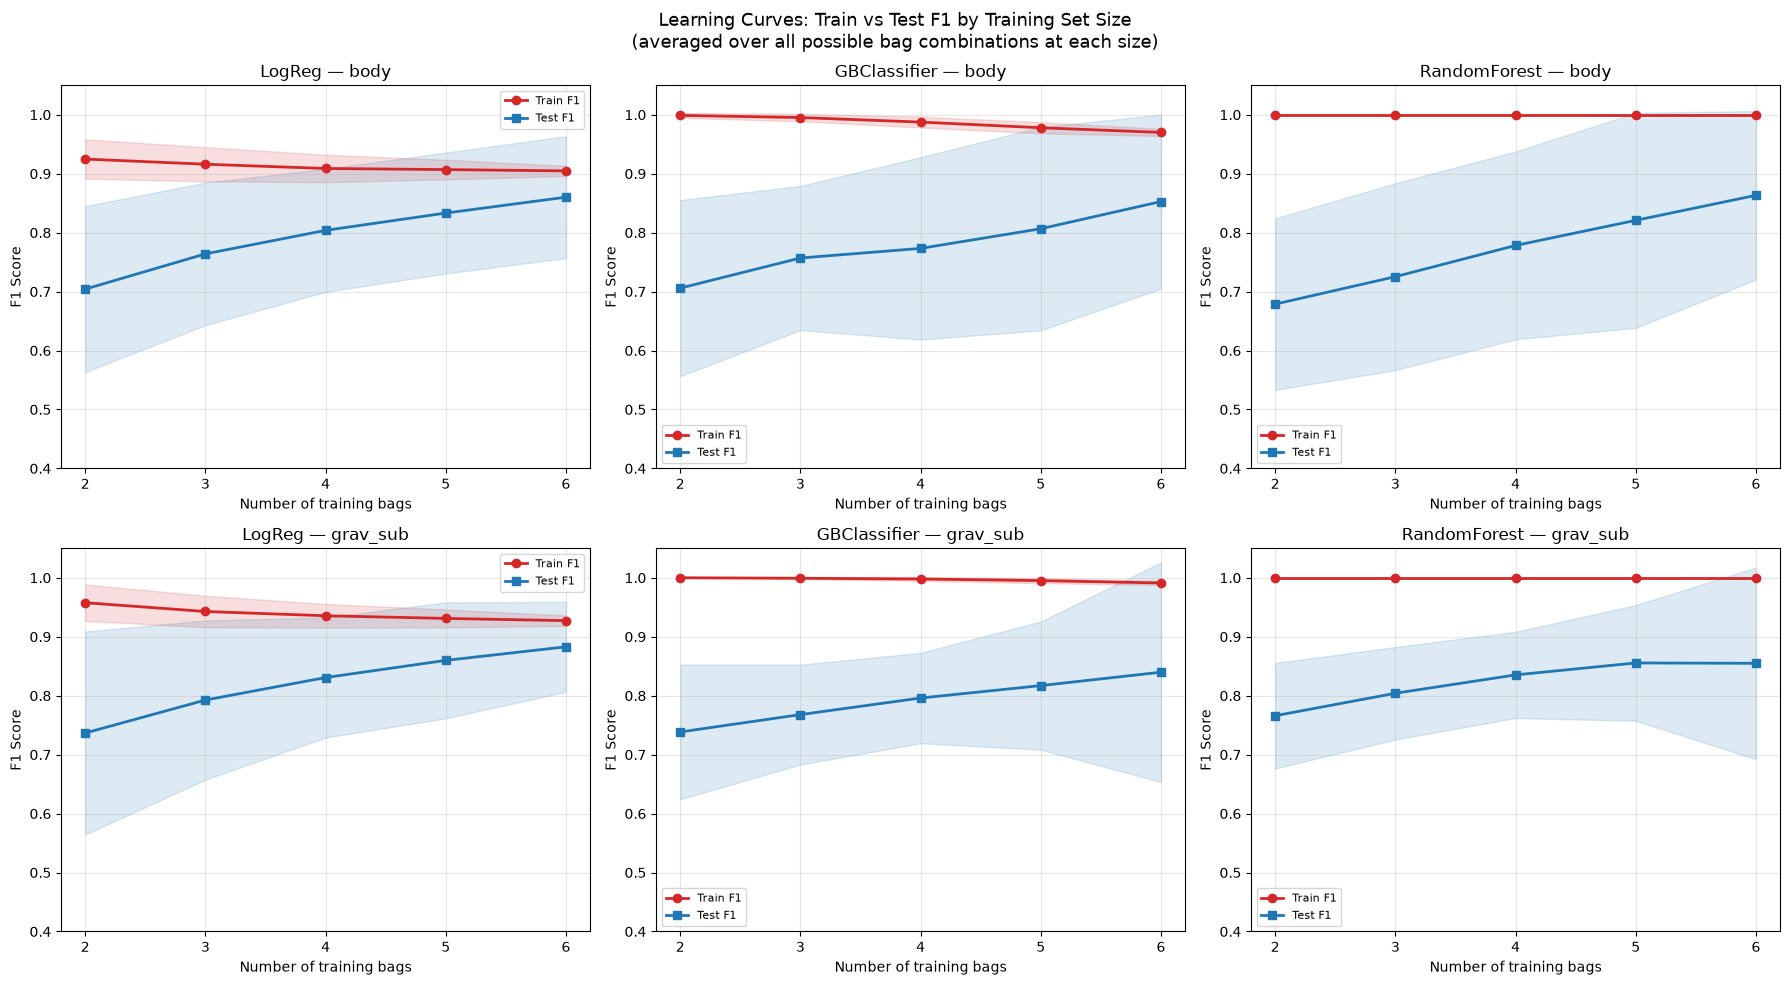


Train-Test F1 Gap at LOBO (6 training bags):
Signal       Classifier      Train F1  Test F1    Gap
-------------------------------------------------------
body         LogReg             0.905    0.860  0.045
body         GBClassifier       0.970    0.853  0.117
body         RandomForest       1.000    0.863  0.137
grav_sub     LogReg             0.927    0.883  0.044
grav_sub     GBClassifier       0.991    0.840  0.151
grav_sub     RandomForest       1.000    0.855  0.145


In [29]:
from itertools import combinations

# Learning curves: train with 2..6 bags, test on each remaining bag
# For each training set size, average over all possible (train, test) splits
all_bag_names = list(bags.keys())
n_bags = len(all_bag_names)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, (clf_name, clf_fn) in enumerate(CLASSIFIERS.items()):
    for row, (sig, feat_key, label_key) in enumerate(SIGNAL_TYPES):
        ax = axes[row, col]
        
        train_sizes = list(range(2, n_bags))  # 2 to 6 training bags
        mean_train_f1s = []
        mean_test_f1s = []
        std_train_f1s = []
        std_test_f1s = []
        
        for k in train_sizes:
            fold_train_f1s = []
            fold_test_f1s = []
            
            for train_combo in combinations(range(n_bags), k):
                test_indices = [i for i in range(n_bags) if i not in train_combo]
                
                train_names = [all_bag_names[i] for i in train_combo]
                
                X_tr = np.vstack([bags[n][feat_key] for n in train_names])
                y_tr = np.concatenate([bags[n][label_key] for n in train_names])
                
                sc = StandardScaler()
                X_tr_s = sc.fit_transform(X_tr)
                
                clf = clf_fn()
                if clf_name == 'GBClassifier':
                    n_p = y_tr.sum()
                    n_n = len(y_tr) - n_p
                    w = np.where(y_tr == 1, n_n / n_p if n_p > 0 else 1.0, 1.0)
                    clf.fit(X_tr_s, y_tr, sample_weight=w)
                else:
                    clf.fit(X_tr_s, y_tr)
                
                train_f1 = f1_score(y_tr, clf.predict(X_tr_s), zero_division=0)
                fold_train_f1s.append(train_f1)
                
                # Average test F1 over all held-out bags
                test_f1s_this = []
                for ti in test_indices:
                    tn = all_bag_names[ti]
                    X_te = sc.transform(bags[tn][feat_key])
                    y_te = bags[tn][label_key]
                    test_f1s_this.append(f1_score(y_te, clf.predict(X_te), zero_division=0))
                fold_test_f1s.append(np.mean(test_f1s_this))
            
            mean_train_f1s.append(np.mean(fold_train_f1s))
            mean_test_f1s.append(np.mean(fold_test_f1s))
            std_train_f1s.append(np.std(fold_train_f1s))
            std_test_f1s.append(np.std(fold_test_f1s))
        
        # Plot
        ax.fill_between(train_sizes,
                        np.array(mean_train_f1s) - np.array(std_train_f1s),
                        np.array(mean_train_f1s) + np.array(std_train_f1s),
                        alpha=0.15, color='tab:red')
        ax.fill_between(train_sizes,
                        np.array(mean_test_f1s) - np.array(std_test_f1s),
                        np.array(mean_test_f1s) + np.array(std_test_f1s),
                        alpha=0.15, color='tab:blue')
        ax.plot(train_sizes, mean_train_f1s, 'o-', color='tab:red', label='Train F1', linewidth=2)
        ax.plot(train_sizes, mean_test_f1s, 's-', color='tab:blue', label='Test F1', linewidth=2)
        
        ax.set_xlabel('Number of training bags')
        ax.set_ylabel('F1 Score')
        ax.set_title(f'{clf_name} — {sig}')
        ax.set_ylim(0.4, 1.05)
        ax.set_xticks(train_sizes)
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

plt.suptitle('Learning Curves: Train vs Test F1 by Training Set Size\n'
             '(averaged over all possible bag combinations at each size)', fontsize=13)
plt.tight_layout()
plt.show()

# Print the train-test gap (overfitting indicator) at full LOBO (6 training bags)
print("\nTrain-Test F1 Gap at LOBO (6 training bags):")
print(f"{'Signal':12s} {'Classifier':14s} {'Train F1':>9s} {'Test F1':>8s} {'Gap':>6s}")
print('-' * 55)
for sig, _, _ in SIGNAL_TYPES:
    for clf_name in CLASSIFIERS:
        r = results[sig][clf_name]
        tr = np.mean(r['train_f1s'])
        te = np.mean(r['f1s'])
        print(f"{sig:12s} {clf_name:14s} {tr:9.3f} {te:8.3f} {tr-te:6.3f}")

## Visual: Peak Detection Overlay — Both Signals

Side-by-side comparison of detected peaks on body-frame vs gravity-subtracted signal for all bags.

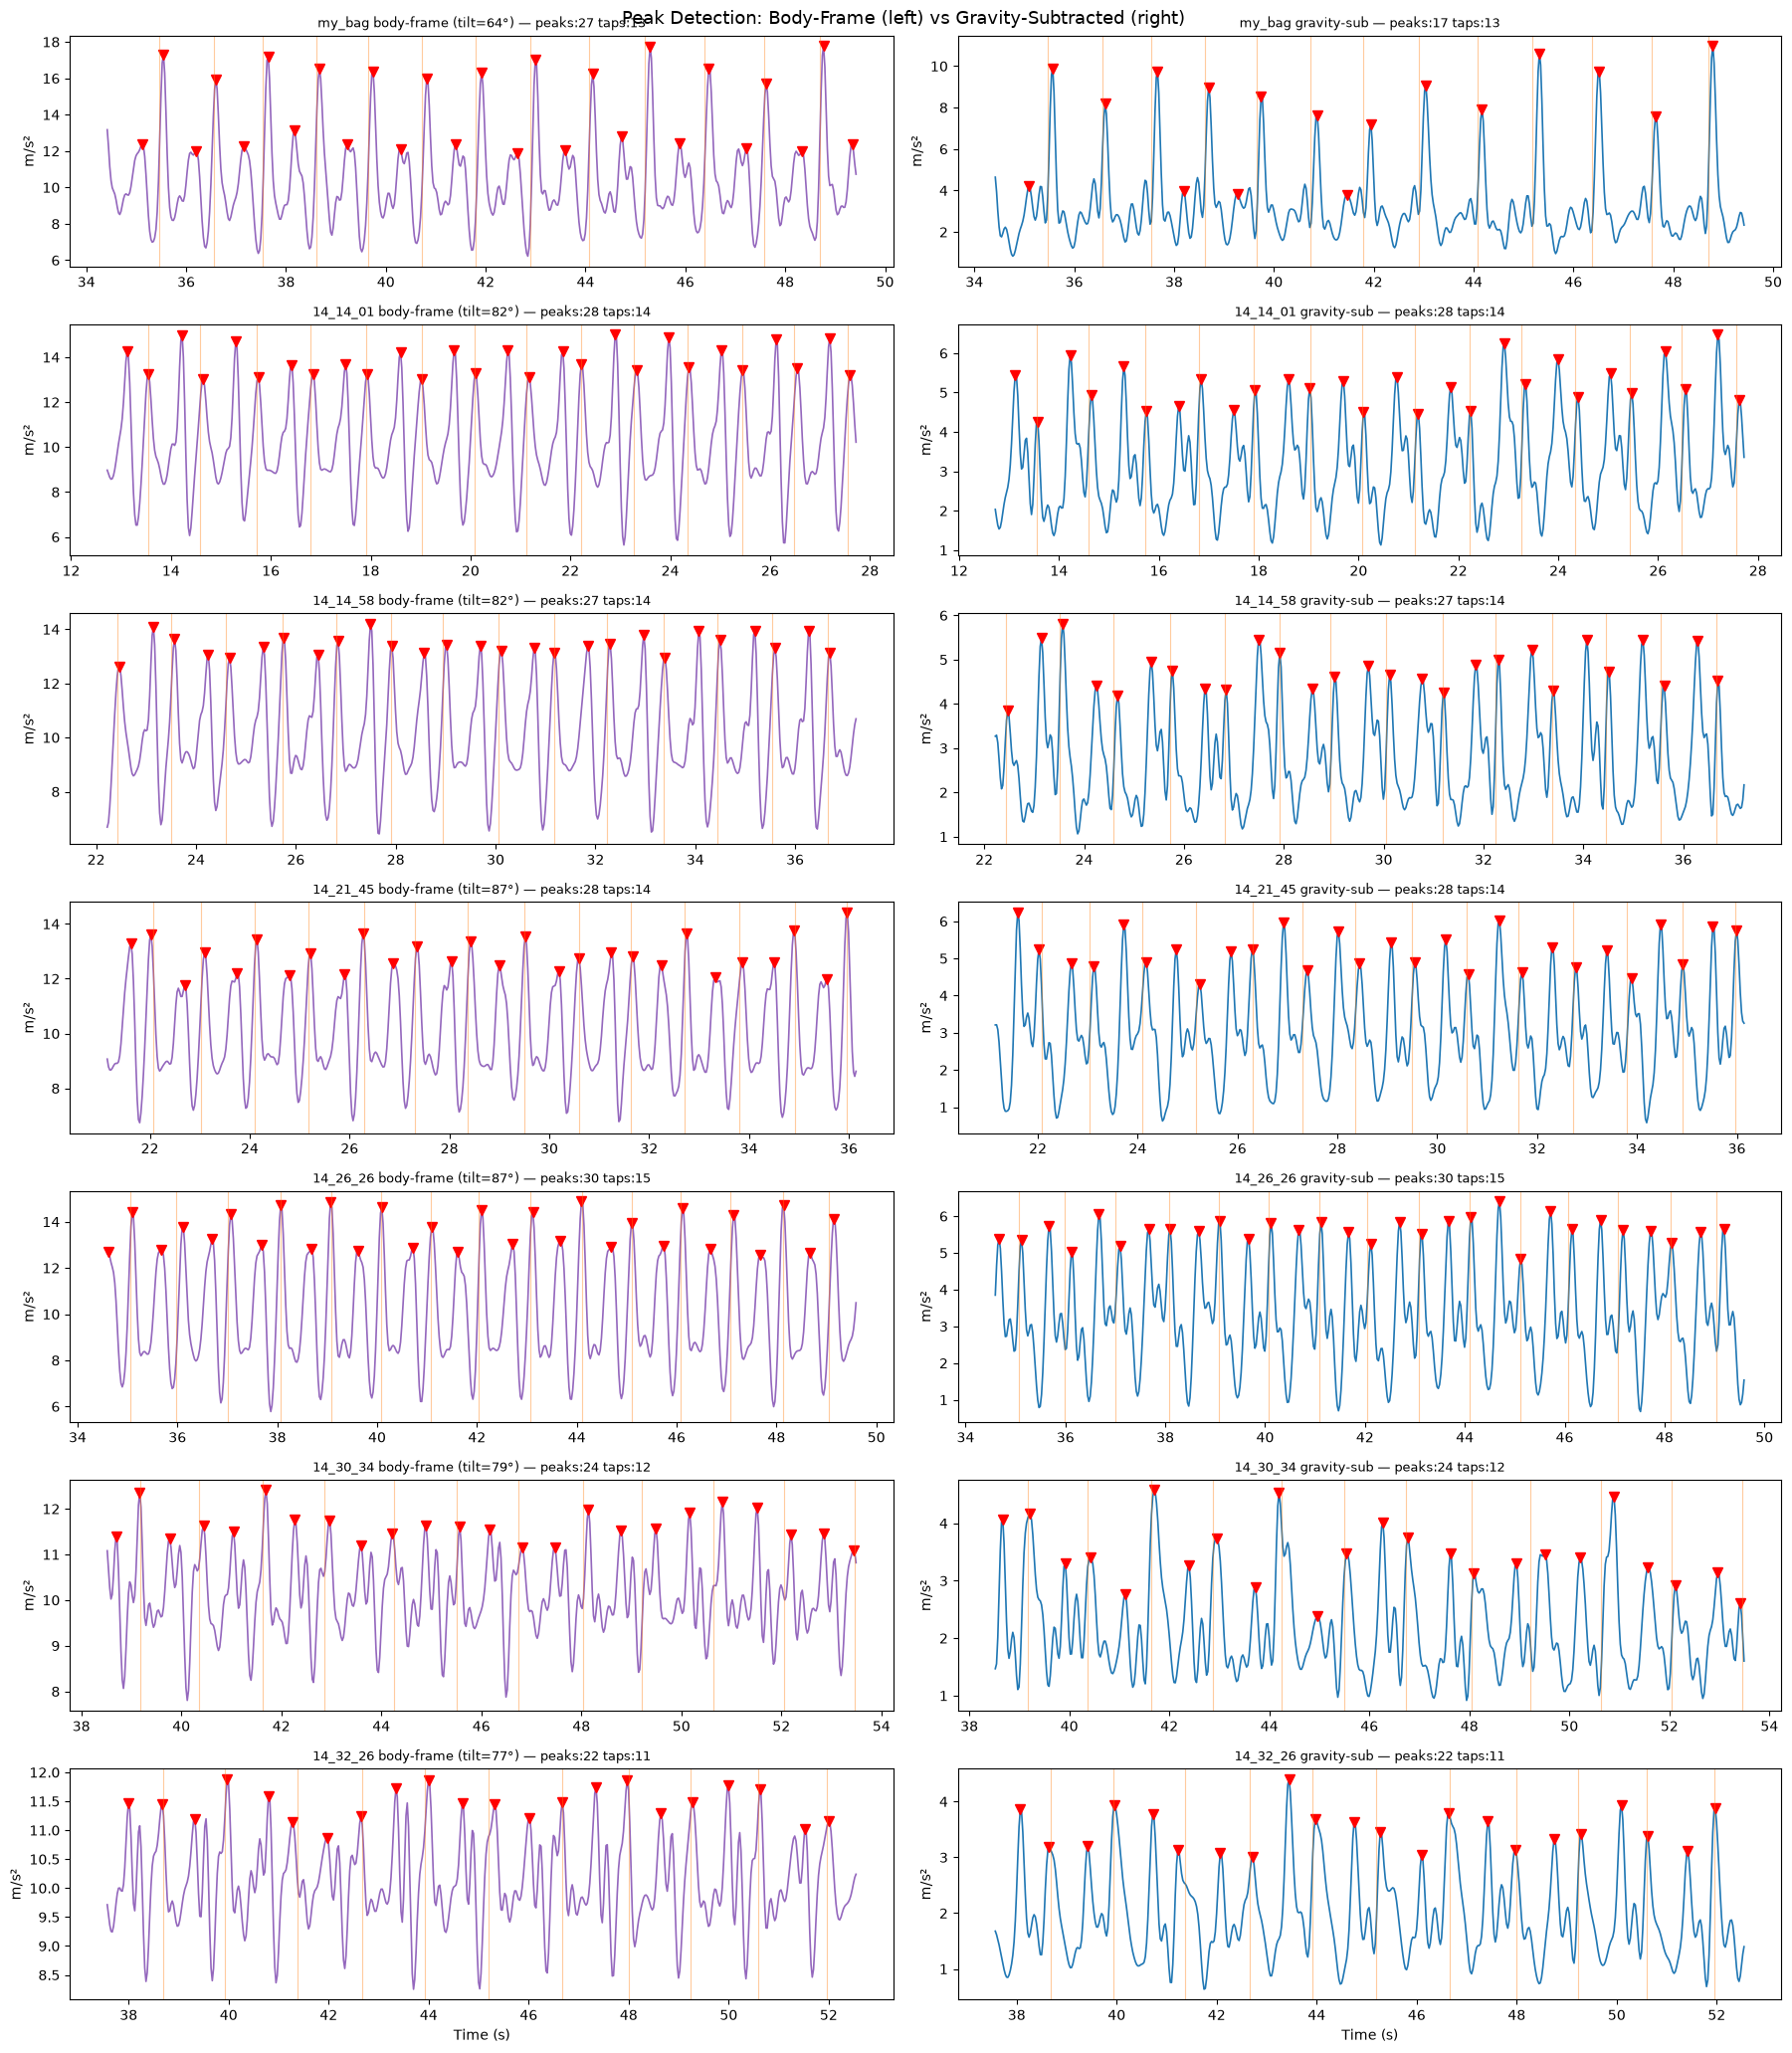

In [30]:
fig, axes = plt.subplots(len(bags), 2, figsize=(18, 3 * len(bags)))

for i, (name, b) in enumerate(bags.items()):
    t = b['timestamps']
    mid = t[-1] / 2
    t_start, t_end = mid - 7.5, mid + 7.5
    mask = (t >= t_start) & (t <= t_end)
    
    # Body-frame
    ax = axes[i, 0]
    ax.plot(t[mask], b['accel_mag_filt'][mask], color='tab:purple', linewidth=1.2)
    pk_times_body = t[b['detected_peaks_body']]
    pk_mask = (pk_times_body >= t_start) & (pk_times_body <= t_end)
    ax.plot(pk_times_body[pk_mask], b['accel_mag_filt'][b['detected_peaks_body'][pk_mask]],
            'rv', markersize=7, label='Detected')
    for tap in b['tap_times']:
        if t_start <= tap <= t_end:
            ax.axvline(tap, color='tab:orange', alpha=0.4, linewidth=0.8)
    n_pk = pk_mask.sum()
    n_tap = sum(1 for tap in b['tap_times'] if t_start <= tap <= t_end)
    ax.set_title(f"{name} body-frame (tilt={b['tilt_deg']:.0f}°) — peaks:{n_pk} taps:{n_tap}", fontsize=9)
    ax.set_ylabel('m/s²')
    
    # Gravity-subtracted dynamic
    ax = axes[i, 1]
    ax.plot(t[mask], b['dyn_mag_filt'][mask], color='tab:blue', linewidth=1.2)
    pk_times_dyn = t[b['detected_peaks_dyn']]
    pk_mask = (pk_times_dyn >= t_start) & (pk_times_dyn <= t_end)
    ax.plot(pk_times_dyn[pk_mask], b['dyn_mag_filt'][b['detected_peaks_dyn'][pk_mask]],
            'rv', markersize=7, label='Detected')
    for tap in b['tap_times']:
        if t_start <= tap <= t_end:
            ax.axvline(tap, color='tab:orange', alpha=0.4, linewidth=0.8)
    n_pk = pk_mask.sum()
    ax.set_title(f"{name} gravity-sub — peaks:{n_pk} taps:{n_tap}", fontsize=9)
    ax.set_ylabel('m/s²')

axes[-1, 0].set_xlabel('Time (s)')
axes[-1, 1].set_xlabel('Time (s)')
plt.suptitle('Peak Detection: Body-Frame (left) vs Gravity-Subtracted (right)', fontsize=13)
plt.tight_layout()
plt.show()

## Average Step Shape Comparison

Overlay the average step shape from all bags — the gravity-subtracted signal should produce more similar shapes since the tilt-dependent gravity baseline is removed.

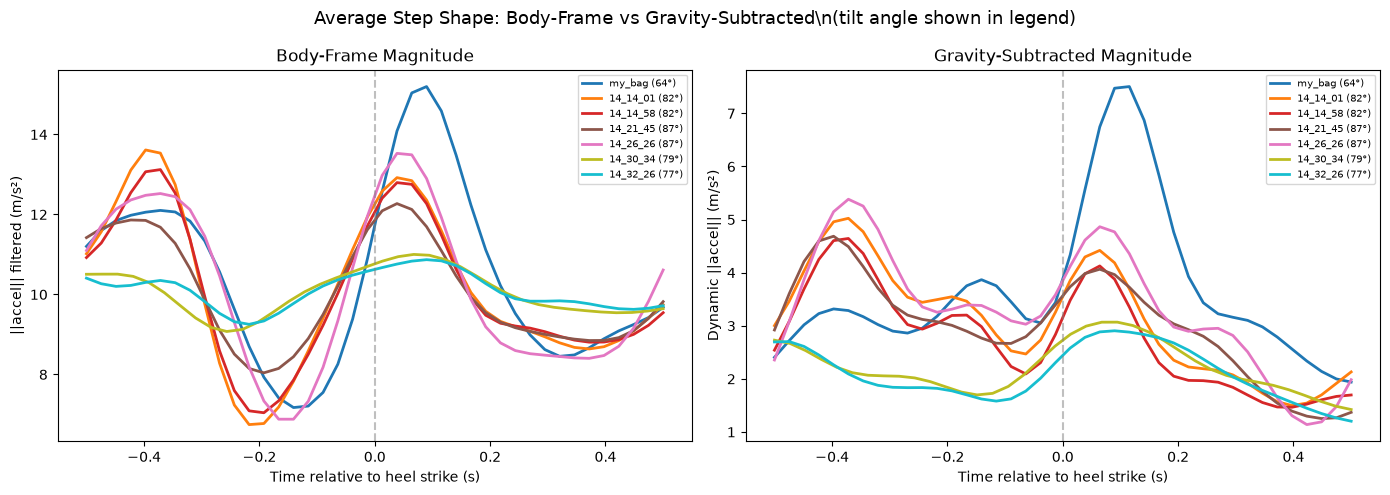

In [31]:
def extract_step_windows(timestamps, signal, tap_times, window_sec=0.5, fs=40.0):
    half = int(window_sec * fs)
    windows = []
    for t in tap_times:
        idx = np.argmin(np.abs(timestamps - t))
        if idx - half >= 0 and idx + half < len(signal):
            windows.append(signal[idx - half:idx + half])
    return np.array(windows) if windows else np.array([]).reshape(0, 2 * half)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.tab10(np.linspace(0, 1, len(bags)))

for (name, b), color in zip(bags.items(), colors):
    fs = b['sample_rate']
    
    # Body-frame
    win = extract_step_windows(b['timestamps'], b['accel_mag_filt'], b['tap_times'], fs=fs)
    if len(win) > 0:
        ta = np.linspace(-0.5, 0.5, win.shape[1])
        axes[0].plot(ta, win.mean(axis=0), linewidth=2, color=color,
                     label=f"{name} ({b['tilt_deg']:.0f}°)")
    
    # Gravity-subtracted dynamic
    win = extract_step_windows(b['timestamps'], b['dyn_mag_filt'], b['tap_times'], fs=fs)
    if len(win) > 0:
        ta = np.linspace(-0.5, 0.5, win.shape[1])
        axes[1].plot(ta, win.mean(axis=0), linewidth=2, color=color,
                     label=f"{name} ({b['tilt_deg']:.0f}°)")

axes[0].axvline(0, color='gray', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Time relative to heel strike (s)')
axes[0].set_ylabel('||accel|| filtered (m/s²)')
axes[0].set_title('Body-Frame Magnitude')
axes[0].legend(fontsize=7)

axes[1].axvline(0, color='gray', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Time relative to heel strike (s)')
axes[1].set_ylabel('Dynamic ||accel|| (m/s²)')
axes[1].set_title('Gravity-Subtracted Magnitude')
axes[1].legend(fontsize=7)

plt.suptitle('Average Step Shape: Body-Frame vs Gravity-Subtracted\\n(tilt angle shown in legend)',
             fontsize=13)
plt.tight_layout()
plt.show()